In [1]:
import json, random, re, warnings
from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from tqdm.auto import tqdm
from skimage import measure, morphology
from skimage.measure import regionprops
from scipy.stats import ks_2samp

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
sns.set_theme(style="whitegrid")

import kagglehub
ROOT = Path(kagglehub.competition_download("filament-segmentation-2026"))

TRAIN_DIR = next(ROOT.rglob("train_images"))
TEST_DIR  = next(ROOT.rglob("test_images"))
IMG_EXTS  = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}
train_paths = sorted(p for p in TRAIN_DIR.iterdir() if p.suffix.lower() in IMG_EXTS)
test_paths  = sorted(p for p in TEST_DIR.iterdir()  if p.suffix.lower() in IMG_EXTS)

ANN_PATH = next(ROOT.rglob("*train*.json"))
with open(ANN_PATH) as f:
    ann_raw = json.load(f)

images_info  = {im["id"]: im for im in ann_raw["images"]}
anns_by_image = defaultdict(list)
for a in ann_raw["annotations"]:
    anns_by_image[a["image_id"]].append(a)
cat_names = {c["id"]: c["name"] for c in ann_raw["categories"]}

name_to_path = {p.name: p for p in train_paths}

def load_image(path):
    img = np.array(Image.open(path))
    if img.ndim == 3:
        img = img[..., :3].mean(axis=2)
    return img.astype(np.float32)

def norm01(img, lo_p=1, hi_p=99):
    lo, hi = np.percentile(img, [lo_p, hi_p])
    return np.clip((img - lo) / max(hi - lo, 1e-6), 0, 1)

def ann_to_mask(ann, h, w):
    mask = np.zeros((h, w), np.uint8)
    for poly in ann["segmentation"]:
        pts = np.asarray(poly, np.float64).reshape(-1, 2)
        cv2.fillPoly(mask, [pts.astype(np.int32)], 1)
    return mask.astype(bool)

def record_mask(image_id):
    info = images_info[image_id]
    h, w = info["height"], info["width"]
    masks = [ann_to_mask(a, h, w) for a in anns_by_image[image_id]]
    return masks, (np.any(masks, axis=0) if masks else np.zeros((h, w), bool))

OUT = Path("nb02_outputs"); OUT.mkdir(exist_ok=True)
print(f"train files={len(train_paths)}  test files={len(test_paths)}  "
      f"json records={len(images_info)}  annotations={len(ann_raw['annotations'])}")


train files=707  test files=180  json records=1154  annotations=8199


In [2]:
# ============ A1: Do multiple JSON records per file = multiple annotation sets? ============
# Method: group records by physical filename; inspect id prefixes; quantify per-record differences.

rec_rows = []
for img_id, info in images_info.items():
    anns = anns_by_image[img_id]
    prefix = img_id.split("-")[0] if "-" in img_id else ""
    rec_rows.append({
        "image_id": img_id,
        "file": Path(info["file_name"]).name,
        "id_prefix": prefix,
        "n_instances": len(anns),
        "total_poly_area": float(sum(a.get("area", 0) for a in anns)),
        "categories": tuple(sorted(Counter(a["category_id"] for a in anns).items())),
    })
rec_df = pd.DataFrame(rec_rows)

per_file = (rec_df.groupby("file")
            .agg(n_records=("image_id", "count"),
                 record_ids=("image_id", list),
                 prefixes=("id_prefix", list),
                 inst_counts=("n_instances", list),
                 areas=("total_poly_area", list))
            .reset_index())

print("Records per physical file:")
print(per_file["n_records"].value_counts().sort_index().to_string())
print(f"\nPhysical files in JSON: {len(per_file)}  (filesystem: {len(train_paths)})")
print("Files in JSON but missing on disk:",
      (~per_file["file"].isin(name_to_path)).sum())
print("Files on disk but absent from JSON:",
      len(set(name_to_path) - set(per_file["file"])))

# Prefix structure: does the prefix encode annotator/task?
prefix_df = rec_df.copy()
print("\nUnique id prefixes:", prefix_df["id_prefix"].nunique())
print(prefix_df["id_prefix"].value_counts().head(20).to_string())
# If prefixes look like e.g. 050101/050102/050103 on the same file,
# check whether the SAME prefix ever repeats across different files:
prefix_file_counts = prefix_df.groupby("id_prefix")["file"].nunique()
print("\nPrefixes used on >1 file:", (prefix_file_counts > 1).sum(),
      "of", len(prefix_file_counts))


Records per physical file:
n_records
1    411
2    145
3    151

Physical files in JSON: 707  (filesystem: 707)
Files in JSON but missing on disk: 0
Files on disk but absent from JSON: 0

Unique id prefixes: 37
id_prefix
010403    77
010402    75
010401    73
010101    72
010102    65
050103    48
030101    48
050101    47
050102    43
060403    43
030302    43
020401    43
040401    43
020403    42
040301    39
040102    39
020101    38
010202    37
010203    37
010103    29

Prefixes used on >1 file: 34 of 37


In [3]:
# Pairwise agreement between annotation records of the same file (full 2048 resolution).
def dice(a, b):
    inter = np.logical_and(a, b).sum()
    s = a.sum() + b.sum()
    return 2 * inter / s if s else 1.0

def iou(a, b):
    inter = np.logical_and(a, b).sum()
    union = np.logical_or(a, b).sum()
    return inter / union if union else 1.0

def instance_pq(masks_a, masks_b):
    """Class-agnostic PQ treating set A as GT, set B as prediction (IoU>0.5 matching)."""
    if not masks_a and not masks_b:
        return 1.0, 0, 0, 0
    ious = np.zeros((len(masks_a), len(masks_b)))
    for i, ma in enumerate(masks_a):
        for j, mb in enumerate(masks_b):
            ious[i, j] = iou(ma, mb)
    matched = ious > 0.5
    tp_iou = ious[matched].sum()
    tp = int(matched.sum())            # unique by PQ theorem (IoU>0.5)
    fn = len(masks_a) - tp
    fp = len(masks_b) - tp
    denom = tp + 0.5 * fp + 0.5 * fn
    return (tp_iou / denom)

Notebook 02 — Forensic Dataset Audit
Cell 0 — Setup, JSON load, record inventory

In [4]:
import json, re, random, warnings
from pathlib import Path
from collections import defaultdict, Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from tqdm.auto import tqdm
from skimage import morphology, measure

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
sns.set_theme(style="whitegrid")

import kagglehub
ROOT = Path(kagglehub.competition_download("filament-segmentation-2026"))

TRAIN_DIR = next(ROOT.rglob("train_images"))
TEST_DIR  = next(ROOT.rglob("test_images"))
ANN_PATH  = next(ROOT.rglob("*.json"))

train_paths = sorted(TRAIN_DIR.glob("*.jpeg")) + sorted(TRAIN_DIR.glob("*.jpg")) + sorted(TRAIN_DIR.glob("*.png"))
test_paths  = sorted(TEST_DIR.glob("*.jpeg"))  + sorted(TEST_DIR.glob("*.jpg"))  + sorted(TEST_DIR.glob("*.png"))

with open(ANN_PATH) as f:
    coco = json.load(f)

CAT_NAMES = {c["id"]: c["name"] for c in coco["categories"]}
records = pd.DataFrame(coco["images"])          # 1154 records
anns    = pd.DataFrame(coco["annotations"])     # 8199 annotations
anns["category"] = anns["category_id"].map(CAT_NAMES)

anns_by_record = defaultdict(list)
for a in coco["annotations"]:
    anns_by_record[a["image_id"]].append(a)

name_to_path = {p.name: p for p in train_paths}
records["file_on_disk"] = records["file_name"].map(
    lambda f: name_to_path.get(Path(f).name))

print(f"JSON records: {len(records)} | unique filenames: {records.file_name.nunique()}")
print(f"Records matched to disk: {records.file_on_disk.notna().sum()}")
print(f"Train files never referenced in JSON: "
      f"{len(set(name_to_path) - set(records.file_name.map(lambda f: Path(f).name)))}")
print(f"Annotations: {len(anns)} | categories: {anns.category.value_counts().to_dict()}")


JSON records: 1154 | unique filenames: 707
Records matched to disk: 1154
Train files never referenced in JSON: 0
Annotations: 8199 | categories: {'Unidentifiable': 3074, 'Right': 2590, 'Left': 2535}


In [5]:
# ---- shared rasterization utilities ----
NATIVE = 2048

def record_masks(image_id, out_size=NATIVE):
    """Instance masks for one JSON record, rasterized at out_size."""
    scale = out_size / NATIVE
    masks, cats = [], []
    for a in anns_by_record[image_id]:
        m = np.zeros((out_size, out_size), np.uint8)
        for poly in a["segmentation"]:
            pts = (np.asarray(poly, np.float64).reshape(-1, 2) * scale)
            cv2.fillPoly(m, [pts.astype(np.int32)], 1)
        masks.append(m.astype(bool)); cats.append(a["category_id"])
    return masks, cats

def record_combined(image_id, out_size=NATIVE):
    masks, _ = record_masks(image_id, out_size)
    return np.any(masks, 0) if masks else np.zeros((out_size, out_size), bool)

def dice(a, b):
    inter = np.logical_and(a, b).sum()
    s = a.sum() + b.sum()
    return 2 * inter / s if s else 1.0

def iou(a, b):
    inter = np.logical_and(a, b).sum()
    union = np.logical_or(a, b).sum()
    return inter / union if union else 1.0

def load_image(path, out_size=None):
    img = np.array(Image.open(path))
    if img.ndim == 3: img = img[..., :3].mean(2)
    if out_size and img.shape[0] != out_size:
        img = cv2.resize(img, (out_size, out_size), interpolation=cv2.INTER_AREA)
    return img.astype(np.float32)

def norm01(img, lo=1, hi=99):
    a, b = np.percentile(img, [lo, hi])
    return np.clip((img - a) / max(b - a, 1e-6), 0, 1)

# Sanity check: is Dice at 1024 a faithful proxy for Dice at 2048?
probe = records.groupby("file_name").filter(lambda g: len(g) >= 2)["file_name"].unique()[:3]
for fn in probe:
    ids = records.loc[records.file_name == fn, "id"].tolist()[:2]
    d_hi = dice(record_combined(ids[0], 2048), record_combined(ids[1], 2048))
    d_lo = dice(record_combined(ids[0], 1024), record_combined(ids[1], 1024))
    print(f"{fn}: Dice@2048={d_hi:.4f}  Dice@1024={d_lo:.4f}  diff={abs(d_hi-d_lo):.4f}")


20111116063134Lh.jpeg: Dice@2048=0.7024  Dice@1024=0.7125  diff=0.0101
20141027025054Uh.jpeg: Dice@2048=0.5869  Dice@1024=0.5948  diff=0.0079
20160714235434Lh.jpeg: Dice@2048=0.6598  Dice@1024=0.6643  diff=0.0045


In [6]:
# A1.1 Group records by physical filename
def record_summary(image_id):
    a_list = anns_by_record[image_id]
    return {
        "n_instances": len(a_list),
        "total_poly_area": sum(a["area"] for a in a_list),
        "categories": Counter(CAT_NAMES[a["category_id"]] for a in a_list),
    }

rows = []
for _, r in records.iterrows():
    s = record_summary(r["id"])
    prefix = r["id"].split("-")[0] if "-" in str(r["id"]) else ""
    rows.append({"file_name": Path(r["file_name"]).name, "record_id": r["id"],
                 "id_prefix": prefix, **s})
rec_df = pd.DataFrame(rows)

per_file = rec_df.groupby("file_name").agg(
    n_records=("record_id", "size"),
    record_ids=("record_id", list),
    prefixes=("id_prefix", list),
    inst_counts=("n_instances", list),
    areas=("total_poly_area", list),
).reset_index()

print("Records per physical file:")
print(per_file.n_records.value_counts().sort_index())
display(per_file[per_file.n_records > 1].head(10))

Records per physical file:
n_records
1    411
2    145
3    151
Name: count, dtype: int64


,file_name,n_records,record_ids,prefixes,inst_counts,areas
1,20110114105034Ch.jpeg,2,"[010101-20110114105034Ch, 010103-2011011410503...","[010101, 010103]","[5, 10]","[8593.0, 5201.0]"
4,20110128174814Mh.jpeg,3,"[010402-20110128174814Mh, 010401-2011012817481...","[010402, 010401, 010403]","[3, 3, 1]","[5646.0, 6394.0, 3139.0]"
5,20110203082634Lh.jpeg,3,"[010102-20110203082634Lh, 010101-2011020308263...","[010102, 010101, 010103]","[1, 5, 2]","[4684.0, 4045.0, 2349.0]"
6,20110205082634Lh.jpeg,2,"[020401-20110205082634Lh, 020403-2011020508263...","[020401, 020403]","[4, 2]","[6464.0, 1817.0]"
8,20110213093414Th.jpeg,2,"[010301-20110213093414Th, 010302-2011021309341...","[010301, 010302]","[5, 5]","[3702.0, 4933.0]"
9,20110215083814Th.jpeg,3,"[010401-20110215083814Th, 010402-2011021508381...","[010401, 010402, 010403]","[5, 4, 4]","[5790.0, 11664.0, 8326.0]"
10,20110220082634Lh.jpeg,2,"[010102-20110220082634Lh, 010101-2011022008263...","[010102, 010101]","[5, 2]","[5677.0, 3751.0]"
12,20110301082654Uh.jpeg,3,"[010403-20110301082654Uh, 010401-2011030108265...","[010403, 010401, 010402]","[2, 1, 4]","[1245.0, 702.0, 3056.0]"
13,20110306082634Lh.jpeg,3,"[010403-20110306082634Lh, 010401-2011030608263...","[010403, 010401, 010402]","[6, 6, 7]","[10923.0, 7355.0, 14208.0]"
17,20110322005814Mh.jpeg,3,"[050101-20110322005814Mh, 050102-2011032200581...","[050101, 050102, 050103]","[1, 1, 1]","[2220.0, 2141.0, 1587.0]"


the next attempt of cloude

In [7]:
# ============================================================
# NOTEBOOK 02 — FORENSIC DATASET AUDIT
# No model training. Purpose: convert uncertainty into evidence.
# ============================================================
import os, json, random, re, warnings, math
from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from tqdm.auto import tqdm
from skimage import measure, morphology
from scipy.stats import ks_2samp, spearmanr

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
sns.set_theme(style="whitegrid")

import kagglehub
ROOT = Path(kagglehub.competition_download("filament-segmentation-2026"))

OUT = Path("nb02_outputs"); OUT.mkdir(exist_ok=True)
IMG_EXTS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}
print("Dataset root:", ROOT)


Dataset root: /kaggle/input/competitions/filament-segmentation-2026


In [8]:
# ---------- 0.1 Robust directory discovery (no silent guessing) ----------

def discover_image_directories(root):
    """Return a DataFrame of every directory that directly contains images."""
    rows = []
    for d in sorted({p.parent for p in root.rglob("*") if p.suffix.lower() in IMG_EXTS}):
        files = [p for p in d.iterdir() if p.suffix.lower() in IMG_EXTS]
        rows.append({
            "dir": d,
            "rel": str(d.relative_to(root)),
            "n_images": len(files),
            "looks_train": bool(re.search(r"train", str(d), re.I)),
            "looks_test":  bool(re.search(r"test",  str(d), re.I)),
        })
    return pd.DataFrame(rows)

dir_df = discover_image_directories(ROOT)
print("Candidate image directories:")
display(dir_df[["rel", "n_images", "looks_train", "looks_test"]])

def select_split_dir(df, flag_col, split_name):
    cands = df[df[flag_col] & ~df[flag_col.replace(flag_col.split('_')[1], 
              'test' if 'train' in flag_col else 'train')]] \
            if False else df[df[flag_col]]
    # exclude dirs that match BOTH train and test patterns
    cands = cands[~(cands["looks_train"] & cands["looks_test"])]
    if len(cands) == 0:
        raise RuntimeError(
            f"No directory matched '{split_name}'. Inspect dir_df above and set "
            f"{split_name.upper()}_DIR manually.")
    if len(cands) > 1:
        # prefer the one with the most images, but refuse near-ties
        cands = cands.sort_values("n_images", ascending=False)
        if len(cands) > 1 and cands.iloc[1]["n_images"] > 0.5 * cands.iloc[0]["n_images"]:
            raise RuntimeError(
                f"Ambiguous '{split_name}' directories:\n"
                f"{cands[['rel','n_images']].to_string()}\n"
                f"Set {split_name.upper()}_DIR manually from the table above.")
    chosen = cands.iloc[0]
    print(f"Selected {split_name} dir: {chosen['rel']}  ({chosen['n_images']} images)")
    return chosen["dir"]

TRAIN_DIR = select_split_dir(dir_df, "looks_train", "train")
TEST_DIR  = select_split_dir(dir_df, "looks_test",  "test")

train_paths = sorted(p for p in TRAIN_DIR.iterdir() if p.suffix.lower() in IMG_EXTS)
test_paths  = sorted(p for p in TEST_DIR.iterdir()  if p.suffix.lower() in IMG_EXTS)
print(f"train files: {len(train_paths)} | test files: {len(test_paths)}")


Candidate image directories:


,rel,n_images,looks_train,looks_test
0,MAGFiLO_1.0_Kaggle_2026/test/test_images,180,False,True
1,MAGFiLO_1.0_Kaggle_2026/train/train_images,707,True,False


Selected train dir: MAGFiLO_1.0_Kaggle_2026/train/train_images  (707 images)
Selected test dir: MAGFiLO_1.0_Kaggle_2026/test/test_images  (180 images)
train files: 707 | test files: 180


In [9]:
# ---------- 0.2 Annotation JSON discovery + load ----------

json_candidates = sorted(ROOT.rglob("*.json"))
print("JSON files found:")
for p in json_candidates:
    print(f"  {p.relative_to(ROOT)}  ({p.stat().st_size/1024:.0f} KB)")

def looks_like_coco(path):
    try:
        with open(path) as f:
            d = json.load(f)
        return isinstance(d, dict) and "images" in d and "annotations" in d
    except Exception:
        return False

coco_paths = [p for p in json_candidates if looks_like_coco(p)]
if len(coco_paths) != 1:
    raise RuntimeError(f"Expected exactly 1 COCO-style JSON, found {len(coco_paths)}: "
                       f"{[str(p) for p in coco_paths]} — choose manually.")
ANN_PATH = coco_paths[0]

with open(ANN_PATH) as f:
    COCO = json.load(f)

images_info  = {im["id"]: im for im in COCO["images"]}
anns_by_image = defaultdict(list)
for a in COCO["annotations"]:
    anns_by_image[a["image_id"]].append(a)
CAT_NAMES = {c["id"]: c["name"] for c in COCO["categories"]}
name_to_path = {p.name: p for p in train_paths}

print(f"\nJSON image records: {len(images_info)} | annotations: {len(COCO['annotations'])}")
print("categories:", CAT_NAMES)


JSON files found:
  MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json  (47477 KB)

JSON image records: 1154 | annotations: 8199
categories: {1: 'Left', 2: 'Right', 3: 'Unidentifiable', 4: 'Ambiguous'}


In [10]:
# ---------- 0.3 Shared utilities (single canonical implementation) ----------

def load_image(path):
    img = np.array(Image.open(path))
    if img.ndim == 3:
        img = img[..., :3].mean(axis=2)
    return img.astype(np.float32)

def norm01(img, lo=1, hi=99):
    a, b = np.percentile(img, [lo, hi])
    return np.zeros_like(img) if b <= a else np.clip((img - a) / (b - a), 0, 1)

# Exploratory rasterization scale. Pairwise agreement, touching and
# resolution analyses run at SCALE to keep runtime tractable on Kaggle.
# Galleries and anything boundary-critical use SCALE=1.0.
SCALE = 0.5

def ann_to_mask(ann, h, w, scale=1.0):
    """Polygon -> boolean mask. Coordinates scaled BEFORE rasterization,
    so thin structures are preserved better than mask-resizing."""
    hh, ww = int(round(h * scale)), int(round(w * scale))
    m = np.zeros((hh, ww), np.uint8)
    for poly in ann["segmentation"]:
        pts = np.asarray(poly, np.float64).reshape(-1, 2) * scale
        cv2.fillPoly(m, [np.round(pts).astype(np.int32)], 1)
    return m.astype(bool)

def record_instance_masks(image_id, scale=1.0):
    info = images_info[image_id]
    return [ann_to_mask(a, info["height"], info["width"], scale)
            for a in anns_by_image[image_id]]

def record_combined_mask(image_id, scale=1.0):
    ms = record_instance_masks(image_id, scale)
    info = images_info[image_id]
    shape = (int(round(info["height"]*scale)), int(round(info["width"]*scale)))
    return np.any(ms, axis=0) if ms else np.zeros(shape, bool)

def dice(a, b):
    s = a.sum() + b.sum()
    return 1.0 if s == 0 else 2 * np.logical_and(a, b).sum() / s

def iou(a, b):
    u = np.logical_or(a, b).sum()
    return 1.0 if u == 0 else np.logical_and(a, b).sum() / u


In [11]:
# ---------- 0.4 Class-agnostic Panoptic Quality + greedy instance matcher ----------
# PQ per Kirillov et al. 2019. IoU>0.5 makes matching unique, so greedy == optimal.
# Whether the competition uses exactly this is UNVERIFIED (see A2).

def match_instances(masks_a, masks_b, iou_thresh=0.5):
    """Greedy matching on descending IoU. Returns (pairs, unmatched_a, unmatched_b).
    pairs = list of (i, j, iou). Greedy is exact for iou_thresh>0.5; for lower
    thresholds it is an approximation — documented and acceptable here."""
    cands = []
    for i, ma in enumerate(masks_a):
        for j, mb in enumerate(masks_b):
            v = iou(ma, mb)
            if v > iou_thresh:
                cands.append((v, i, j))
    cands.sort(reverse=True)
    used_a, used_b, pairs = set(), set(), []
    for v, i, j in cands:
        if i not in used_a and j not in used_b:
            pairs.append((i, j, v)); used_a.add(i); used_b.add(j)
    un_a = [i for i in range(len(masks_a)) if i not in used_a]
    un_b = [j for j in range(len(masks_b)) if j not in used_b]
    return pairs, un_a, un_b

def panoptic_quality(gt_masks, pred_masks, iou_thresh=0.5):
    if not gt_masks and not pred_masks:
        return dict(PQ=1.0, SQ=1.0, RQ=1.0, TP=0, FP=0, FN=0)
    pairs, un_gt, un_pred = match_instances(gt_masks, pred_masks, iou_thresh)
    tp, fp, fn = len(pairs), len(un_pred), len(un_gt)
    rq = tp / (tp + 0.5*fp + 0.5*fn) if (tp+fp+fn) else 1.0
    sq = float(np.mean([v for *_, v in pairs])) if pairs else 0.0
    return dict(PQ=sq*rq, SQ=sq, RQ=rq, TP=tp, FP=fp, FN=fn)

# sanity tests
_a = np.zeros((20, 20), bool); _a[5:10, 5:15] = True
assert panoptic_quality([_a], [_a.copy()])["PQ"] == 1.0
_f1, _f2 = _a.copy(), _a.copy(); _f1[:, 10:] = False; _f2[:, :10] = False
assert panoptic_quality([_a], [_f1, _f2])["PQ"] == 0.0   # fragmentation -> no match
assert panoptic_quality([_a], [])["RQ"] == 0.0
print("PQ sanity checks passed")


PQ sanity checks passed


In [12]:
# ---------- 0.4 Class-agnostic Panoptic Quality + greedy instance matcher ----------
# PQ per Kirillov et al. 2019. IoU>0.5 makes matching unique, so greedy == optimal.
# Whether the competition uses exactly this is UNVERIFIED (see A2).

def match_instances(masks_a, masks_b, iou_thresh=0.5):
    """Greedy matching on descending IoU. Returns (pairs, unmatched_a, unmatched_b).
    pairs = list of (i, j, iou). Greedy is exact for iou_thresh>0.5; for lower
    thresholds it is an approximation — documented and acceptable here."""
    cands = []
    for i, ma in enumerate(masks_a):
        for j, mb in enumerate(masks_b):
            v = iou(ma, mb)
            if v > iou_thresh:
                cands.append((v, i, j))
    cands.sort(reverse=True)
    used_a, used_b, pairs = set(), set(), []
    for v, i, j in cands:
        if i not in used_a and j not in used_b:
            pairs.append((i, j, v)); used_a.add(i); used_b.add(j)
    un_a = [i for i in range(len(masks_a)) if i not in used_a]
    un_b = [j for j in range(len(masks_b)) if j not in used_b]
    return pairs, un_a, un_b

def panoptic_quality(gt_masks, pred_masks, iou_thresh=0.5):
    if not gt_masks and not pred_masks:
        return dict(PQ=1.0, SQ=1.0, RQ=1.0, TP=0, FP=0, FN=0)
    pairs, un_gt, un_pred = match_instances(gt_masks, pred_masks, iou_thresh)
    tp, fp, fn = len(pairs), len(un_pred), len(un_gt)
    rq = tp / (tp + 0.5*fp + 0.5*fn) if (tp+fp+fn) else 1.0
    sq = float(np.mean([v for *_, v in pairs])) if pairs else 0.0
    return dict(PQ=sq*rq, SQ=sq, RQ=rq, TP=tp, FP=fp, FN=fn)

# sanity tests
_a = np.zeros((20, 20), bool); _a[5:10, 5:15] = True
assert panoptic_quality([_a], [_a.copy()])["PQ"] == 1.0
_f1, _f2 = _a.copy(), _a.copy(); _f1[:, 10:] = False; _f2[:, :10] = False
assert panoptic_quality([_a], [_f1, _f2])["PQ"] == 0.0   # fragmentation -> no match
assert panoptic_quality([_a], [])["RQ"] == 0.0
print("PQ sanity checks passed")


PQ sanity checks passed


In [13]:
# Research question: do 1154 JSON records over ~707 files represent
# multiple annotation sets per physical image (H1)?

rec_rows = []
for img_id, info in images_info.items():
    anns = anns_by_image[img_id]
    rec_rows.append({
        "image_id": img_id,
        "file": Path(info["file_name"]).name,
        "prefix": img_id.split("-")[0],
        "n_instances": len(anns),
        "cat_counts": dict(Counter(CAT_NAMES[a["category_id"]] for a in anns)),
        "total_poly_area": float(sum(a.get("area", 0) for a in anns)),
        "on_disk": Path(info["file_name"]).name in name_to_path,
    })
rec_df = pd.DataFrame(rec_rows)

grp = rec_df.groupby("file").agg(
    n_records=("image_id", "count"),
    record_ids=("image_id", list),
    prefixes=("prefix", list),
    instances_per_record=("n_instances", list),
    areas_per_record=("total_poly_area", list),
).reset_index()

print("Records per physical file:")
print(grp["n_records"].value_counts().sort_index().to_string())
print(f"\nPhysical files referenced by JSON: {len(grp)}")
print(f"Train files on disk:               {len(train_paths)}")
print(f"JSON records whose file is missing on disk: {(~rec_df.on_disk).sum()}")

multi = grp[grp["n_records"] > 1].reset_index(drop=True)
single = grp[grp["n_records"] == 1]
print(f"\nMulti-record files: {len(multi)} | single-record files: {len(single)}")
display(multi.head(8))


Records per physical file:
n_records
1    411
2    145
3    151

Physical files referenced by JSON: 707
Train files on disk:               707
JSON records whose file is missing on disk: 0

Multi-record files: 296 | single-record files: 411


,file,n_records,record_ids,prefixes,instances_per_record,areas_per_record
0,20110114105034Ch.jpeg,2,"[010101-20110114105034Ch, 010103-2011011410503...","[010101, 010103]","[5, 10]","[8593.0, 5201.0]"
1,20110128174814Mh.jpeg,3,"[010402-20110128174814Mh, 010401-2011012817481...","[010402, 010401, 010403]","[3, 3, 1]","[5646.0, 6394.0, 3139.0]"
2,20110203082634Lh.jpeg,3,"[010102-20110203082634Lh, 010101-2011020308263...","[010102, 010101, 010103]","[1, 5, 2]","[4684.0, 4045.0, 2349.0]"
3,20110205082634Lh.jpeg,2,"[020401-20110205082634Lh, 020403-2011020508263...","[020401, 020403]","[4, 2]","[6464.0, 1817.0]"
4,20110213093414Th.jpeg,2,"[010301-20110213093414Th, 010302-2011021309341...","[010301, 010302]","[5, 5]","[3702.0, 4933.0]"
5,20110215083814Th.jpeg,3,"[010401-20110215083814Th, 010402-2011021508381...","[010401, 010402, 010403]","[5, 4, 4]","[5790.0, 11664.0, 8326.0]"
6,20110220082634Lh.jpeg,2,"[010102-20110220082634Lh, 010101-2011022008263...","[010102, 010101]","[5, 2]","[5677.0, 3751.0]"
7,20110301082654Uh.jpeg,3,"[010403-20110301082654Uh, 010401-2011030108265...","[010403, 010401, 010402]","[2, 1, 4]","[1245.0, 702.0, 3056.0]"


In [14]:
# Prefix forensics: is the id prefix structured (annotator/task code)?
pfx = rec_df["prefix"]
print("prefix length distribution:", dict(Counter(pfx.str.len())))
print("unique prefixes:", pfx.nunique())

if (pfx.str.len() == 6).all():
    parts = pd.DataFrame({"d01": pfx.str[:2], "d23": pfx.str[2:4], "d45": pfx.str[4:6]})
    for c in parts:
        print(f"{c}:", dict(parts[c].value_counts()))

    def varying_positions(prefix_list):
        arr = [[p[:2], p[2:4], p[4:6]] for p in prefix_list]
        arr = list(zip(*arr))
        return tuple(len(set(x)) > 1 for x in arr)

    multi["varying_pairs"] = multi["prefixes"].apply(varying_positions)
    print("\nWhich digit-pairs vary WITHIN a multi-record file "
          "(True in exactly one slot => that slot indexes the annotation set):")
    print(multi["varying_pairs"].value_counts().to_string())


prefix length distribution: {6: 1154}
unique prefixes: 37
d01: {'01': np.int64(516), '05': np.int64(180), '04': np.int64(156), '02': np.int64(125), '03': np.int64(111), '06': np.int64(66)}
d23: {'01': np.int64(453), '04': np.int64(419), '03': np.int64(143), '02': np.int64(139)}
d45: {'01': np.int64(463), '02': np.int64(384), '03': np.int64(307)}

Which digit-pairs vary WITHIN a multi-record file (True in exactly one slot => that slot indexes the annotation set):
varying_pairs
(False, False, True)    296


In [15]:
# Combined-mask agreement + instance-level matching for every pair of
# records of the same file. Rasterized at SCALE for tractability.
# Method note: instance matching = greedy descending-IoU (exact for thr>0.5);
# we additionally record best-IoU per instance at NO threshold to separate
# boundary disagreement from object-presence disagreement.

CACHE = OUT / "a1_pairs.csv"
INST_CACHE = OUT / "a1_instances.csv"

if CACHE.exists() and INST_CACHE.exists():
    pair_df = pd.read_csv(CACHE)
    inst_df = pd.read_csv(INST_CACHE)
else:
    pair_rows, inst_rows = [], []
    for _, row in tqdm(multi.iterrows(), total=len(multi)):
        ids = row["record_ids"]
        inst = {i: record_instance_masks(i, SCALE) for i in ids}
        comb = {i: (np.any(inst[i], axis=0) if inst[i] else None) for i in ids}
        for ia, ib in combinations(ids, 2):
            A, B = inst[ia], inst[ib]
            ca, cb = comb[ia], comb[ib]
            pairs, un_a, un_b = match_instances(A, B, iou_thresh=0.5)
            pq = panoptic_quality(A, B)

            # per-instance best IoU with NO threshold (for disagreement typing)
            for i, m in enumerate(A):
                best = max((iou(m, n) for n in B), default=0.0)
                inst_rows.append({"file": row["file"], "record": ia, "other": ib,
                                  "inst_area_px": int(m.sum() / SCALE**2),
                                  "best_iou": best})
            for j, n in enumerate(B):
                best = max((iou(n, m) for m in A), default=0.0)
                inst_rows.append({"file": row["file"], "record": ib, "other": ia,
                                  "inst_area_px": int(n.sum() / SCALE**2),
                                  "best_iou": best})

            matched_ious = [v for *_, v in pairs]
            pair_rows.append({
                "file": row["file"], "id_a": ia, "id_b": ib,
                "dice": dice(ca, cb), "iou": iou(ca, cb),
                "area_a": int(ca.sum()/SCALE**2), "area_b": int(cb.sum()/SCALE**2),
                "area_ratio": ca.sum()/max(cb.sum(), 1),
                "abs_area_diff": abs(int(ca.sum()) - int(cb.sum())) / SCALE**2,
                "n_inst_a": len(A), "n_inst_b": len(B),
                "n_matched": len(pairs),
                "n_unmatched_a": len(un_a), "n_unmatched_b": len(un_b),
                "matched_iou_mean": float(np.mean(matched_ious)) if matched_ious else np.nan,
                "matched_iou_min": float(np.min(matched_ious)) if matched_ious else np.nan,
                "pq": pq["PQ"], "sq": pq["SQ"], "rq": pq["RQ"],
            })
    pair_df = pd.DataFrame(pair_rows); pair_df.to_csv(CACHE, index=False)
    inst_df = pd.DataFrame(inst_rows); inst_df.to_csv(INST_CACHE, index=False)

print("=== combined-mask (pixel) agreement ===")
display(pair_df[["dice", "iou", "area_ratio", "abs_area_diff"]].describe().round(3))
print("=== instance-level agreement (PQ@0.5, greedy matching) ===")
display(pair_df[["pq", "sq", "rq", "n_matched", "n_unmatched_a", "n_unmatched_b"]]
        .describe().round(3))


  0%|          | 0/296 [00:00<?, ?it/s]

=== combined-mask (pixel) agreement ===


,dice,iou,area_ratio,abs_area_diff
count,598.000,598.000,598.000,598.000
mean,0.632,0.475,1.131,5713.017
std,0.135,0.135,0.713,6373.729
min,0.000,0.000,0.119,4.000
25%,0.567,0.395,0.741,1373.000
50%,0.661,0.494,0.992,3664.000
75%,0.724,0.568,1.318,7967.000
max,0.895,0.810,5.715,61392.000


=== instance-level agreement (PQ@0.5, greedy matching) ===


,pq,sq,rq,n_matched,n_unmatched_a,n_unmatched_b
count,598.000,598.000,598.000,598.000,598.000,598.000
mean,0.377,0.621,0.580,3.871,2.824,2.809
std,0.165,0.137,0.242,2.793,2.668,2.576
min,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.274,0.606,0.429,2.000,1.000,1.000
50%,0.383,0.643,0.594,3.000,2.000,2.000
75%,0.491,0.683,0.750,6.000,4.000,4.000
max,0.810,0.810,1.000,13.000,17.000,14.000


Instance-level disagreement composition (all record pairs):
status
matched                  0.579
boundary_disagreement    0.233
presence_disagreement    0.188

Is disagreement concentrated on small instances?


,count,mean,std,min,25%,50%,75%,max
status,,,,,,,,
presence_disagreement,1500.0,1504.0,2028.0,20.0,572.0,918.0,1596.0,22616.0
boundary_disagreement,1867.0,3084.0,3416.0,156.0,1084.0,2004.0,3632.0,40528.0
matched,4632.0,2842.0,3232.0,160.0,1072.0,1776.0,3357.0,34124.0



Per-pair dominant disagreement type:
disagreement_type
presence-dominant    0.682
boundary-dominant    0.308
high-agreement       0.008
mixed                0.002


Text(0.5, 1.0, 'Mean IoU of MATC')

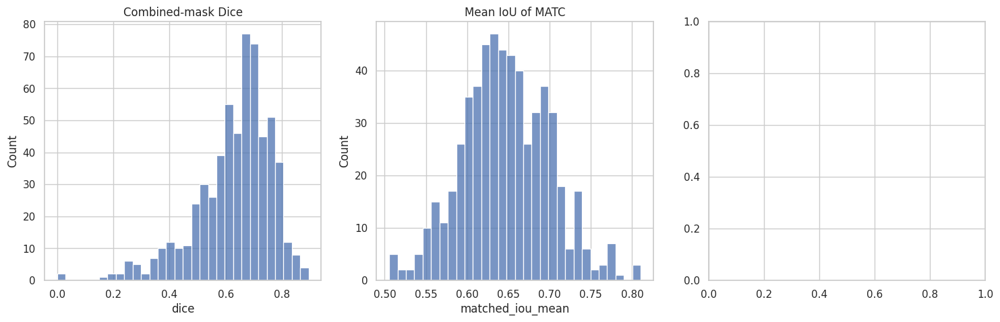

In [16]:
# Instance status by unthresholded best-IoU:
#   best_iou > 0.5   -> same object, boundary agreement good enough to match
#   0.1..0.5         -> same object probably present, boundaries disagree (BOUNDARY)
#   <= 0.1           -> object effectively absent in the other annotation (PRESENCE)
BOUNDARY_LO, MATCH_THR = 0.1, 0.5

inst_df["status"] = pd.cut(inst_df["best_iou"],
                           [-0.01, BOUNDARY_LO, MATCH_THR, 1.01],
                           labels=["presence_disagreement",
                                   "boundary_disagreement", "matched"])

print("Instance-level disagreement composition (all record pairs):")
print(inst_df["status"].value_counts(normalize=True).round(3).to_string())

print("\nIs disagreement concentrated on small instances?")
display(inst_df.groupby("status")["inst_area_px"].describe().round(0))

# per-pair dominant disagreement type
def classify_pair(r):
    total = r["n_inst_a"] + r["n_inst_b"]
    unmatched = r["n_unmatched_a"] + r["n_unmatched_b"]
    presence_frac = unmatched / max(total, 1)
    boundary_bad = (r["matched_iou_mean"] < 0.75) if not np.isnan(r["matched_iou_mean"]) else False
    if presence_frac > 0.3:   return "presence-dominant"
    if boundary_bad:          return "boundary-dominant"
    if presence_frac > 0.1:   return "mixed"
    return "high-agreement"

pair_df["disagreement_type"] = pair_df.apply(classify_pair, axis=1)
print("\nPer-pair dominant disagreement type:")
print(pair_df["disagreement_type"].value_counts(normalize=True).round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(pair_df["dice"], bins=30, ax=axes[0]); axes[0].set_title("Combined-mask Dice")
sns.histplot(pair_df["matched_iou_mean"].dropna(), bins=30, ax=axes[1])
axes[1].set_title("Mean IoU of MATC")

In [17]:
axes[1].set_title("Mean IoU of MATCHED instances (boundary quality)")
sns.histplot(inst_df["best_iou"], bins=40, ax=axes[2])
axes[2].axvline(BOUNDARY_LO, color="red", ls="--")
axes[2].axvline(MATCH_THR, color="orange", ls="--")
axes[2].set_title("Per-instance best IoU (red=presence thr, orange=match thr)")
plt.tight_layout(); plt.savefig(OUT / "a1_disagreement_hists.png", dpi=100); plt.show()

# small-vs-large presence disagreement rate
inst_df["size_bin"] = pd.cut(inst_df["inst_area_px"],
                             [0, 300, 1000, 3000, 10**9],
                             labels=["<300px", "300-1k", "1k-3k", ">3k"])
presence_rate = (inst_df.assign(is_presence=inst_df["status"] == "presence_disagreement")
                 .groupby("size_bin")["is_presence"].mean())
print("\nPresence-disagreement rate by instance size:")
print(presence_rate.round(3).to_string())


<Figure size 640x480 with 0 Axes>


Presence-disagreement rate by instance size:
size_bin
<300px    0.583
300-1k    0.355
1k-3k     0.144
>3k       0.074


GALLERY 1 — boundary disagreement (4 examples)


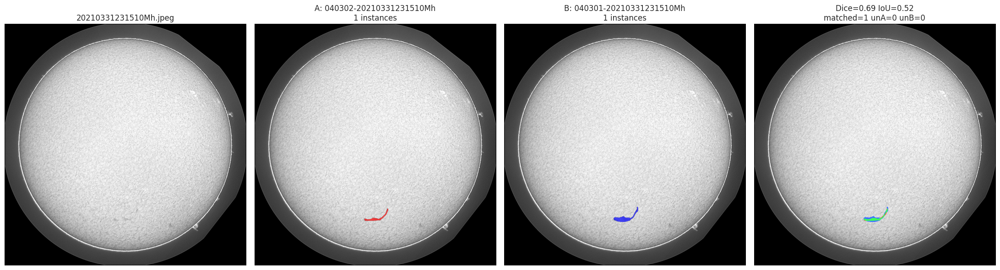

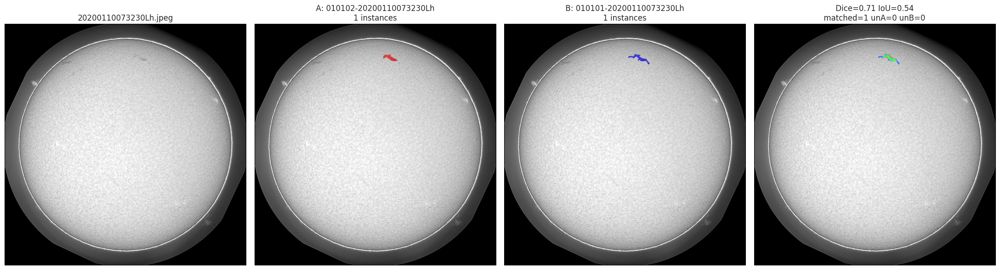

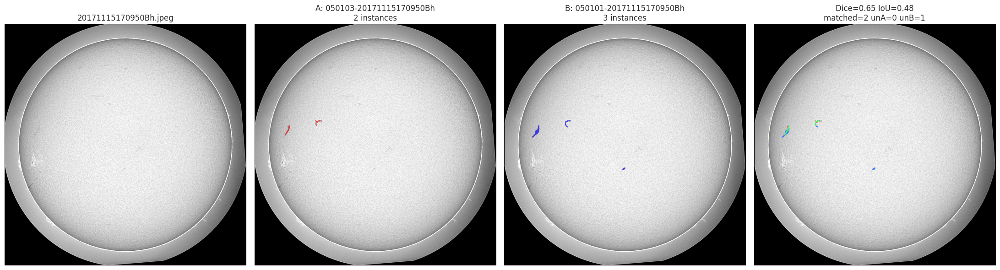

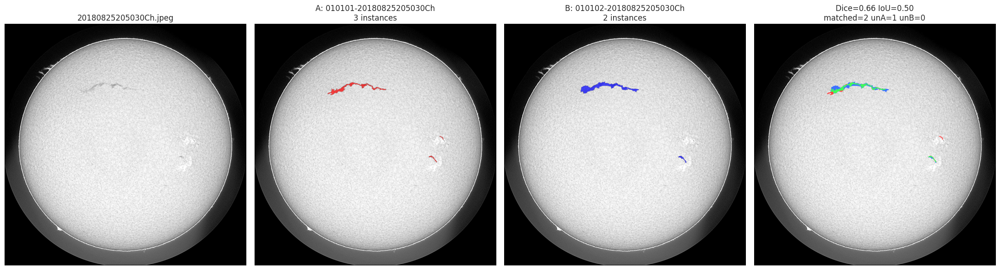

GALLERY 2 — presence disagreement (4 examples)


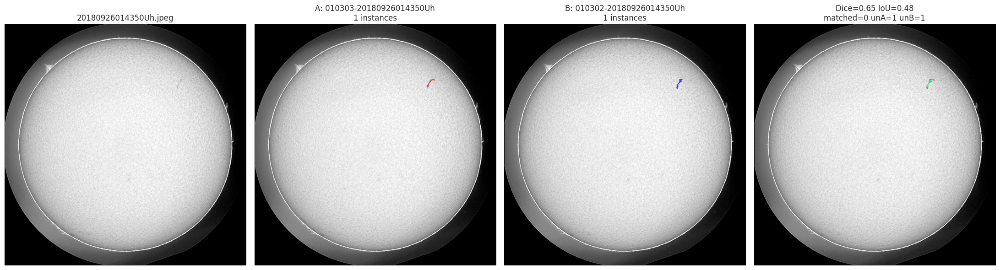

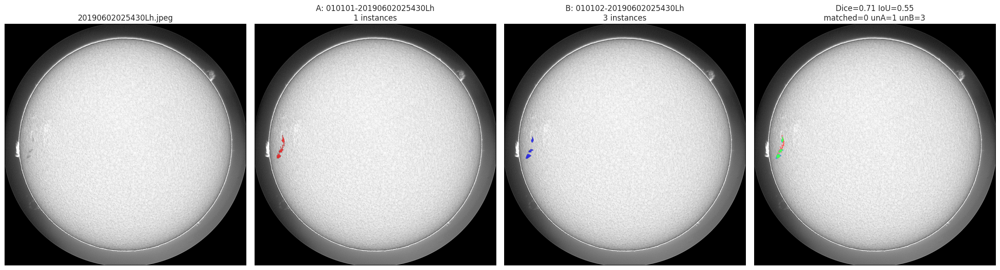

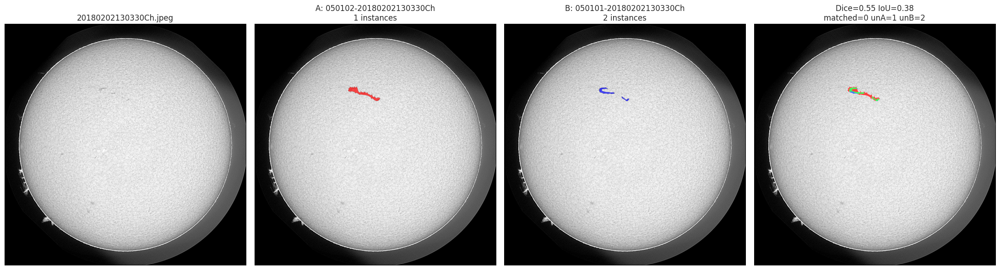

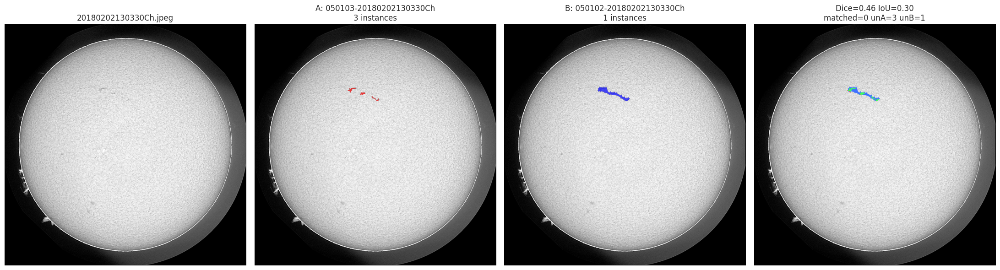

In [18]:
# Full-resolution rendering for galleries (boundary-critical -> scale=1.0)

def disagreement_panel(file, id_a, id_b, meta, save_name):
    img = norm01(load_image(name_to_path[file]))
    a = record_combined_mask(id_a, scale=1.0)
    b = record_combined_mask(id_b, scale=1.0)

    fig, axes = plt.subplots(1, 4, figsize=(22, 6))
    axes[0].imshow(img, cmap="gray"); axes[0].set_title(file)

    axes[1].imshow(img, cmap="gray")
    axes[1].imshow(np.ma.masked_where(~a, a), cmap="autumn", alpha=0.7)
    axes[1].set_title(f"A: {id_a}\n{meta['n_inst_a']} instances")

    axes[2].imshow(img, cmap="gray")
    axes[2].imshow(np.ma.masked_where(~b, b), cmap="winter", alpha=0.7)
    axes[2].set_title(f"B: {id_b}\n{meta['n_inst_b']} instances")

    rgb = np.stack([img]*3, -1)
    rgb[a & ~b] = [1.0, 0.25, 0.25]   # red: A only
    rgb[~a & b] = [0.25, 0.45, 1.0]   # blue: B only
    rgb[a & b]  = [0.25, 1.0, 0.35]   # green: agreement
    axes[3].imshow(rgb)
    axes[3].set_title(f"Dice={meta['dice']:.2f} IoU={meta['iou']:.2f}\n"
                      f"matched={meta['n_matched']} "
                      f"unA={meta['n_unmatched_a']} unB={meta['n_unmatched_b']}")
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.savefig(OUT / save_name, dpi=90); plt.show()


# Gallery 1: high overlap, but boundary disagreement
g1 = (pair_df[(pair_df["disagreement_type"] == "boundary-dominant")]
      .sort_values("matched_iou_mean").head(4))
if len(g1) == 0:   # fallback: high dice, lowest matched IoU
    g1 = pair_df[pair_df["dice"] > pair_df["dice"].median()] \
         .sort_values("matched_iou_mean").head(4)
print(f"GALLERY 1 — boundary disagreement ({len(g1)} examples)")
for k, (_, r) in enumerate(g1.iterrows()):
    disagreement_panel(r["file"], r["id_a"], r["id_b"], r, f"a1_gal1_boundary_{k}.png")

# Gallery 2: instance-presence disagreement
g2 = (pair_df[pair_df["disagreement_type"] == "presence-dominant"]
      .sort_values("rq").head(4))
if len(g2) == 0:
    g2 = pair_df.sort_values(["n_unmatched_a", "n_unmatched_b"], ascending=False).head(4)
print(f"GALLERY 2 — presence disagreement ({len(g2)} examples)")
for k, (_, r) in enumerate(g2.iterrows()):
    disagreement_panel(r["file"], r["id_a"], r["id_b"], r, f"a1_gal2_presence_{k}.png")


In [19]:
# Code can only inspect files shipped inside the dataset.
# Anything not confirmed here stays labeled UNVERIFIED.

print("All non-image files in the competition download:")
for p in sorted(ROOT.rglob("*")):
    if p.is_file() and p.suffix.lower() not in IMG_EXTS:
        print(f"  {p.relative_to(ROOT)}  ({p.stat().st_size/1024:.1f} KB)")

sub_candidates = [p for p in ROOT.rglob("*") if p.is_file()
                  and re.search(r"sample|submission|solution|eval", p.name, re.I)]
if not sub_candidates:
    print("\nNo sample-submission-like file found in the download.")
for p in sub_candidates:
    print(f"\n=== {p.name} ===")
    if p.suffix.lower() == ".csv":
        s = pd.read_csv(p)
        print("shape:", s.shape, "| columns:", list(s.columns))
        display(s.head(10))
        # RLE heuristic: long space-separated digit strings
        for c in s.columns:
            v = s[c].astype(str).iloc[0]
            if re.fullmatch(r"[\d ]{20,}", v):
                print(f"  column '{c}' looks like RLE")
    elif p.suffix.lower() == ".json":
        with open(p) as f:
            print(json.dumps(json.load(f), indent=2)[:2000])


All non-image files in the competition download:
  MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json  (47477.2 KB)

No sample-submission-like file found in the download.


In [20]:
# Hypothesis: filename = YYYYMMDDHHMMSS + station letter + 'h'
FN_RE = re.compile(r"^(\d{4})(\d{2})(\d{2})(\d{2})(\d{2})(\d{2})([A-Za-z])h\.", re.I)
STATION_GUESS = {"B": "Big Bear", "C": "Cerro Tololo", "L": "Learmonth",
                 "M": "Mauna Loa", "T": "El Teide", "U": "Udaipur"}

def parse_fn(p, split):
    m = FN_RE.match(p.name)
    if not m:
        return {"file": p.name, "split": split, "parsed": False}
    y, mo, d, h, mi, s, st = m.groups()
    return {"file": p.name, "split": split, "parsed": True,
            "date": f"{y}-{mo}-{d}", "year": int(y), "month": int(mo),
            "station": st.upper(),
            "ts": pd.Timestamp(f"{y}-{mo}-{d} {h}:{mi}:{s}")}

meta_df = pd.DataFrame([parse_fn(p, "train") for p in train_paths] +
                       [parse_fn(p, "test") for p in test_paths])
print(f"Filenames parsed: {meta_df['parsed'].mean():.1%}")
if meta_df["parsed"].mean() < 1.0:
    print("UNPARSED:", meta_df.loc[~meta_df.parsed, "file"].tolist()[:10])

m = meta_df[meta_df.parsed]
print("\nStation counts (train/test):")
display(pd.crosstab(m["station"], m["split"]))
print("Station letter -> GONG site guess:", STATION_GUESS)
print("\nYear distribution:")
display(pd.crosstab(m["year"], m["split"]))
print(f"\nUnique dates: {m['date'].nunique()} across {len(m)} images")
per_date = m.groupby("date").size()
print("images per date:", per_date.describe().round(2).to_dict())


Filenames parsed: 100.0%

Station counts (train/test):


split,test,train
station,,
B,33,118
C,33,125
L,34,127
M,26,125
T,27,110
U,27,102


Station letter -> GONG site guess: {'B': 'Big Bear', 'C': 'Cerro Tololo', 'L': 'Learmonth', 'M': 'Mauna Loa', 'T': 'El Teide', 'U': 'Udaipur'}

Year distribution:


split,test,train
year,,
2011,24,86
2012,23,92
2013,23,101
2014,22,102
2015,17,86
2016,22,80
2017,19,71
2018,4,26
2019,2,14



Unique dates: 801 across 887 images
images per date: {'count': 801.0, 'mean': 1.11, 'std': 0.33, 'min': 1.0, '25%': 1.0, '50%': 1.0, '75%': 1.0, 'max': 3.0}


In [21]:
# Same-day cross-split contamination + near-duplicate check
date_split = m.groupby("date")["split"].nunique()
both = date_split[date_split > 1].index
print(f"Dates present in BOTH train and test: {len(both)} / {m['date'].nunique()}")
if len(both):
    print("examples:", list(both[:10]))

# visual near-duplicate measure for same-day pairs (downsampled correlation)
def thumb(p, size=128):
    img = norm01(load_image(p))
    return cv2.resize(img, (size, size)).ravel()

same_day_rows = []
for date, g in tqdm(m[m.split == "train"].groupby("date")):
    if len(g) < 2:
        continue
    paths = [name_to_path[f] for f in g["file"] if f in name_to_path]
    thumbs = [thumb(p) for p in paths]
    for (i, j) in combinations(range(len(thumbs)), 2):
        r = float(np.corrcoef(thumbs[i], thumbs[j])[0, 1])
        same_day_rows.append({"date": date, "corr": r})
sd_df = pd.DataFrame(same_day_rows)

# baseline: random cross-date pairs
rand_rows = []
files = m[m.split == "train"]["file"].tolist()
for _ in range(300):
    f1, f2 = random.sample(files, 2)
    if m.set_index("file").loc[f1, "date"] == m.set_index("file").loc[f2, "date"]:
        continue
    r = float(np.corrcoef(thumb(name_to_path[f1]), thumb(name_to_path[f2]))[0, 1])
    rand_rows.append(r)

print(f"same-day pair correlation:   median={sd_df['corr'].median():.3f}" if len(sd_df) else "no same-day train pairs")
print(f"cross-date pair correlation: median={np.median(rand_rows):.3f}")
print("\n-> If same-day >> cross-date, random splits leak near-duplicates.")
print("Candidate grouping keys for CV: date | station+date | year-month.")
meta_df.to_csv(OUT / "a3_metadata.csv", index=False)


Dates present in BOTH train and test: 31 / 801
examples: ['2011-04-29', '2011-06-03', '2011-11-14', '2011-12-08', '2012-02-18', '2012-07-30', '2012-08-13', '2012-10-24', '2013-01-10', '2013-02-08']


  0%|          | 0/656 [00:00<?, ?it/s]

same-day pair correlation:   median=0.970
cross-date pair correlation: median=0.964

-> If same-day >> cross-date, random splits leak near-duplicates.
Candidate grouping keys for CV: date | station+date | year-month.


In [22]:
# Structure inspection first — no assumptions about format.
spine_anns = [a for a in COCO["annotations"] if a.get("spine") not in (None, [], "")]
print(f"annotations with non-empty spine: {len(spine_anns)} / {len(COCO['annotations'])}")

for a in spine_anns[:3]:
    sp = a["spine"]
    print("\ntype:", type(sp).__name__, "| len:", len(sp) if hasattr(sp, "__len__") else "-")
    print("preview:", str(sp)[:300])


annotations with non-empty spine: 8199 / 8199

type: list | len: 54
preview: [388.7268, 805.455, 394.4037, 809.9707, 396.7261, 811.0029, 399.0485, 811.3899, 401.6289, 811.2609, 406.6607, 809.9707, 412.7246, 807.7774, 416.8533, 806.2291, 420.4659, 805.326, 422.2722, 805.1969, 425.8847, 805.584, 428.4651, 806.7452, 431.8197, 809.0676, 436.2064, 813.4543, 440.7221, 818.6151, 44

type: list | len: 20
preview: [433.2831, 1310.7166, 448.6422, 1328.9199, 459.5926, 1340.0126, 465.9923, 1344.1368, 478.9337, 1349.3987, 488.3198, 1351.5319, 495.2883, 1351.5319, 500.6924, 1349.9676, 507.092, 1344.5634, 523.3044, 1329.3466]

type: list | len: 38
preview: [778.8281, 719.511, 767.5568, 713.9816, 765.2346, 712.1157, 762.7575, 708.9216, 761.7146, 706.3142, 759.2607, 692.5463, 758.9102, 676.4246, 762.9836, 656.2185, 763.7882, 653.483, 767.0065, 648.4946, 768.9374, 645.1154, 771.0293, 637.8743, 772.6384, 621.1393, 772.7758, 595.1334, 772.1779, 589.9517, 7


In [23]:
# Adjust this parser if the printout above shows a different convention.
def spine_to_points(spine):
    """Assumes flat [x1,y1,x2,y2,...] or [[x,y],...] — verify against printout."""
    arr = np.asarray(spine, dtype=np.float64)
    if arr.ndim == 1:
        arr = arr.reshape(-1, 2)
    return arr

sp_rows = []
for a in tqdm(spine_anns):
    info = images_info[a["image_id"]]
    try:
        pts = spine_to_points(a["spine"])
    except Exception:
        continue
    mask = ann_to_mask(a, info["height"], info["width"])
    xs = np.clip(pts[:, 0].round().astype(int), 0, info["width"] - 1)
    ys = np.clip(pts[:, 1].round().astype(int), 0, info["height"] - 1)
    inside_frac = float(mask[ys, xs].mean())
    seglen = float(np.sum(np.hypot(*np.diff(pts, axis=0).T)))
    skel = morphology.skeletonize(mask)
    sp_rows.append({"image_id": a["image_id"], "ann_id": a["id"],
                    "n_points": len(pts), "spine_len": seglen,
                    "inside_mask_frac": inside_frac,
                    "skel_len": int(skel.sum()), "mask_area": int(mask.sum()),
                    "spine_skel_ratio": seglen / max(skel.sum(), 1)})
spine_df = pd.DataFrame(sp_rows)
display(spine_df.describe().round(2))
print("\ninside_mask_frac ~1.0 => spine is a centerline inside the mask")
print("spine_skel_ratio < 1 => spine ignores barbs (main axis only)")
spine_df.to_csv(OUT / "a4_spine.csv", index=False)


  0%|          | 0/8199 [00:00<?, ?it/s]

,n_points,spine_len,inside_mask_frac,skel_len,mask_area,spine_skel_ratio
count,8199.00,8199.00,8199.00,8199.00,8199.00,8199.00
mean,12.48,147.43,0.98,178.31,2293.13,0.92
std,9.01,118.88,0.06,159.61,2858.74,0.99
min,2.00,12.07,0.00,2.00,18.00,0.27
25%,7.00,70.55,1.00,75.00,757.50,0.75
50%,10.00,111.27,1.00,130.00,1365.00,0.90
75%,16.00,182.49,1.00,224.00,2646.00,1.07
max,122.00,1104.95,1.00,1770.00,39060.00,86.09



inside_mask_frac ~1.0 => spine is a centerline inside the mask
spine_skel_ratio < 1 => spine ignores barbs (main axis only)


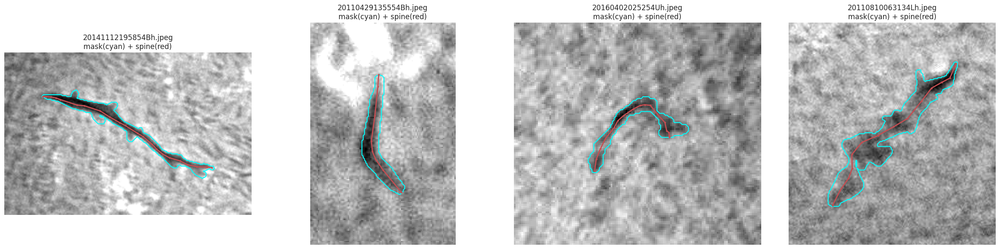

In [24]:
# Visual check: image + mask + polygon + spine
sample = random.sample(spine_anns, min(4, len(spine_anns)))
fig, axes = plt.subplots(1, len(sample), figsize=(6 * len(sample), 6))
for ax, a in zip(np.atleast_1d(axes), sample):
    info = images_info[a["image_id"]]
    fname = Path(info["file_name"]).name
    if fname not in name_to_path:
        continue
    mask = ann_to_mask(a, info["height"], info["width"])
    ys, xs = np.where(mask)
    y0, y1, x0, x1 = ys.min()-40, ys.max()+40, xs.min()-40, xs.max()+40
    img = norm01(load_image(name_to_path[fname]))
    ax.imshow(img[y0:y1, x0:x1], cmap="gray")
    ax.contour(mask[y0:y1, x0:x1], levels=[0.5], colors="cyan")
    pts = spine_to_points(a["spine"])
    ax.plot(pts[:, 0] - x0, pts[:, 1] - y0, "r.-", lw=2, ms=4)
    ax.set_title(f"{fname}\nmask(cyan) + spine(red)"); ax.axis("off")
plt.tight_layout(); plt.savefig(OUT / "a4_spine_gallery.png", dpi=90); plt.show()


In [25]:
cat_series = pd.Series([CAT_NAMES[a["category_id"]] for a in COCO["annotations"]])
print("Instances per category:")
print(cat_series.value_counts().to_string())
print("\nPercentages:")
print(cat_series.value_counts(normalize=True).round(3).to_string())

cat_rows = []
for a in COCO["annotations"]:
    info = images_info[a["image_id"]]
    cx = np.mean(np.asarray(a["segmentation"][0][::2]))
    cy = np.mean(np.asarray(a["segmentation"][0][1::2]))
    r_norm = math.hypot(cx - info["width"]/2, cy - info["height"]/2) / (info["width"]/2)
    cat_rows.append({"cat": CAT_NAMES[a["category_id"]],
                     "area": a.get("area", np.nan), "r_norm": r_norm})
cat_df = pd.DataFrame(cat_rows)
display(cat_df.groupby("cat").agg(n=("area", "count"),
                                  median_area=("area", "median"),
                                  median_radius=("r_norm", "median")).round(3))
print("\nWhether categories affect SCORING is UNVERIFIED (see A2).")
print("Left/Right = chirality; if metric is class-agnostic, treat as one class.")


Instances per category:
Unidentifiable    3074
Right             2590
Left              2535

Percentages:
Unidentifiable    0.375
Right             0.316
Left              0.309


,n,median_area,median_radius
cat,,,
Left,2535,1438.0,0.505
Right,2590,1524.0,0.491
Unidentifiable,3074,868.5,0.544



Whether categories affect SCORING is UNVERIFIED (see A2).
Left/Right = chirality; if metric is class-agnostic, treat as one class.


In [26]:
# How often do different GT instances (within ONE annotation record)
# come within k px of each other? Determines whether CC-from-semantic-mask
# can recover instances.
DILATE_KS = [1, 3, 5, 10]
CACHE6 = OUT / "a6_touching.csv"

if CACHE6.exists():
    touch_df = pd.read_csv(CACHE6)
else:
    rows = []
    for img_id in tqdm(list(images_info.keys())):
        masks = record_instance_masks(img_id, SCALE)
        if len(masks) < 2:
            continue
        for k in DILATE_KS:
            kk = max(1, int(round(k * SCALE)))
            kernel = np.ones((2*kk+1, 2*kk+1), np.uint8)
            dil = [cv2.dilate(m.astype(np.uint8), kernel).astype(bool) for m in masks]
            n_close = sum(1 for i, j in combinations(range(len(masks)), 2)
                          if (dil[i] & masks[j]).any() or (dil[j] & masks[i]).any())
            rows.append({"image_id": img_id, "k_px": k,
                         "n_inst": len(masks), "n_close_pairs": n_close})
    touch_df = pd.DataFrame(rows); touch_df.to_csv(CACHE6, index=False)

summary = touch_df.groupby("k_px").agg(
    frac_images_with_close_pair=("n_close_pairs", lambda s: (s > 0).mean()),
    total_close_pairs=("n_close_pairs", "sum")).round(3)
print("Distinct GT instances within k px of each other:")
display(summary)
print("Direct overlap (k=1 includes touching):",
      f"{(touch_df[touch_df.k_px==1].n_close_pairs > 0).mean():.1%} of multi-instance records")
print("\n-> Low values: semantic mask + connected components may suffice for instances.")
print("-> High values: explicit instance separation needed.")


  0%|          | 0/1154 [00:00<?, ?it/s]

Distinct GT instances within k px of each other:


,frac_images_with_close_pair,total_close_pairs
k_px,,
1,0.033,40
3,0.053,64
5,0.053,64
10,0.122,161


Direct overlap (k=1 includes touching): 3.3% of multi-instance records

-> Low values: semantic mask + connected components may suffice for instances.
-> High values: explicit instance separation needed.


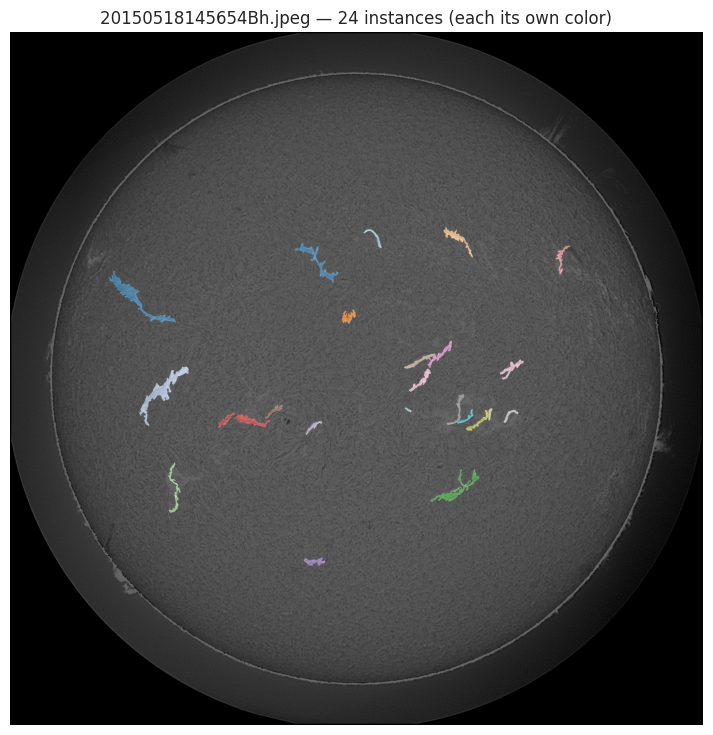

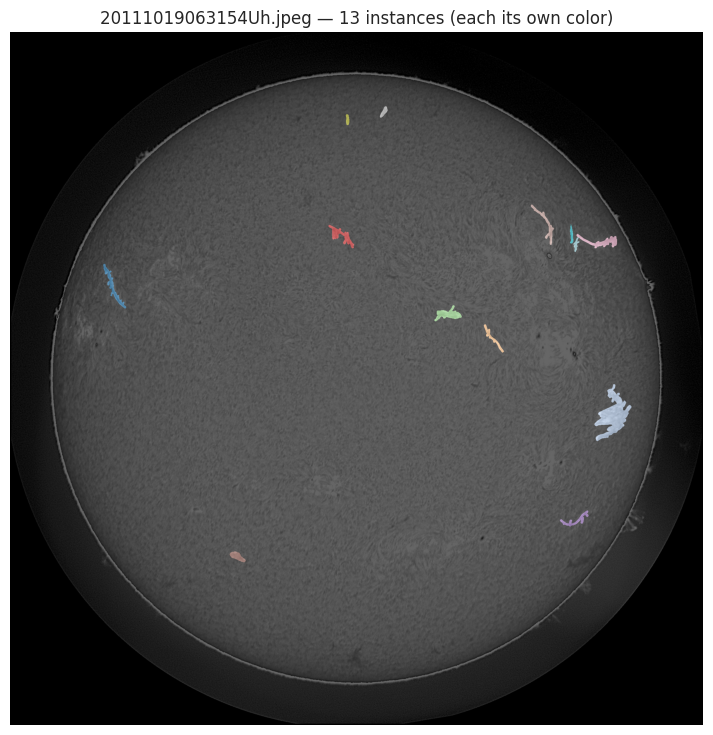

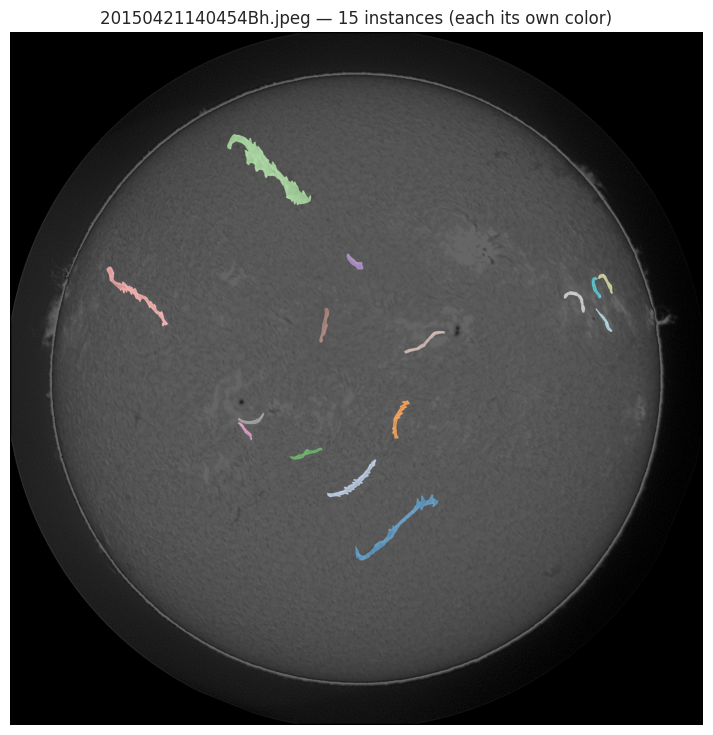

In [27]:
# visual examples of closest instance pairs
worst = (touch_df[touch_df.k_px == 3].sort_values("n_close_pairs", ascending=False)
         .head(3)["image_id"])
for img_id in worst:
    fname = Path(images_info[img_id]["file_name"]).name
    if fname not in name_to_path:
        continue
    masks = record_instance_masks(img_id)
    img = norm01(load_image(name_to_path[fname]))
    vis = np.zeros((*masks[0].shape, 3))
    colors = plt.cm.tab20(np.linspace(0, 1, len(masks)))
    for c, mm in zip(colors, masks):
        vis[mm] = c[:3]
    fig, ax = plt.subplots(figsize=(9, 9))
    ax.imshow(img, cmap="gray"); ax.imshow(vis, alpha=0.6)
    ax.set_title(f"{fname} — {len(masks)} instances (each its own color)")
    ax.axis("off"); plt.show()


  0%|          | 0/887 [00:00<?, ?it/s]

ON-DISK stats train vs test:


split               test    train
disk_mean count   180.00   707.00
          mean    113.13   112.74
          std       3.28     2.79
          min     106.95   104.17
          25%     110.90   110.67
          50%     112.24   112.43
          75%     114.59   114.22
          max     132.89   125.69
disk_std  count   180.00   707.00
          mean     34.48    35.11
          std       5.93     5.16
          min      15.48    18.35
          25%      31.58    32.45
          50%      36.16    36.53
          75%      39.09    39.19
          max      42.35    41.86
disk_p05  count   180.00   707.00
          mean     34.72    32.66
          std      20.53    18.02
          min      10.00     9.75
          25%      19.44    18.88
          50%      27.50    27.75
          75%      45.12    43.12
          max     105.00    91.50
disk_p95  count   180.00   707.00
          mean    145.49   145.35
          std       2.75     2.53
          min     140.75   137.00
          25%     143.75   143.75
          50%     145.25   145.25
          75%     146.50   146.50
          max     157.25   161.50
disk_R_px count   180.00   707.00
          mean   1031.74  1031.67
          std       9.40     5.30
          min     908.99   968.21
          25%    1032.51  1032.29
          50%    1033.07  1033.02
          75%    1033.34  1033.33
          max    1033.47  1033.47

disk_mean: KS=0.068 p=0.4883
disk_std: KS=0.064 p=0.5668
disk_p95: KS=0.040 p=0.9655


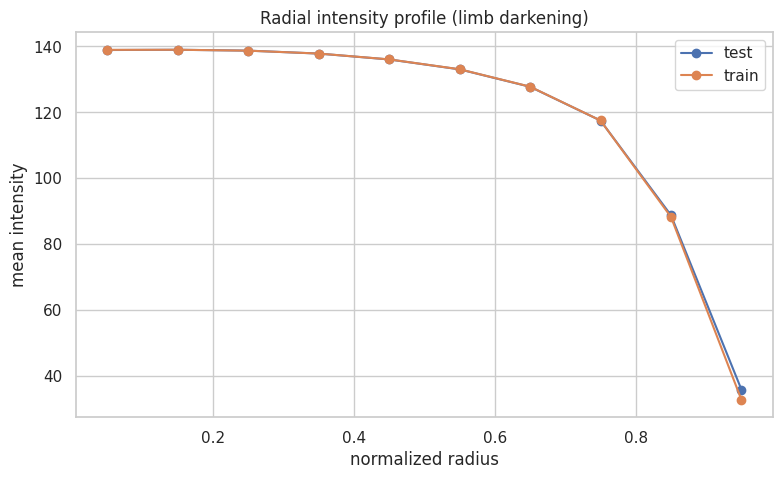

In [28]:
def disk_geometry(img):
    """Estimate disk center/radius via threshold + largest region."""
    t = img > np.percentile(img, 20)
    t = morphology.remove_small_objects(t, 5000)
    lab = measure.label(t)
    props = measure.regionprops(lab)
    if not props:
        h, w = img.shape; return h/2, w/2, min(h, w)/2
    r = max(props, key=lambda p: p.area)
    cy, cx = r.centroid
    return cy, cx, math.sqrt(r.area / math.pi)

CACHE7 = OUT / "a7_photometry.csv"
if CACHE7.exists():
    phot_df = pd.read_csv(CACHE7)
else:
    rows = []
    for p, split in tqdm([(p, "train") for p in train_paths] +
                         [(p, "test") for p in test_paths]):
        img = load_image(p)
        small = cv2.resize(img, (512, 512)); f = 512 / img.shape[0]
        cy, cx, R = disk_geometry(small)
        yy, xx = np.mgrid[0:512, 0:512]
        rr = np.hypot(yy - cy, xx - cx) / R
        inside = rr < 0.95
        vals = small[inside]
        prof = [float(small[(rr >= a) & (rr < a+0.1)].mean()) for a in np.arange(0, 1, 0.1)]
        rows.append({"file": p.name, "split": split, "disk_R_px": R / f,
                     "disk_mean": float(vals.mean()), "disk_std": float(vals.std()),
                     "disk_p05": float(np.percentile(vals, 5)),
                     "disk_p95": float(np.percentile(vals, 95)),
                     **{f"prof_{i}": v for i, v in enumerate(prof)}})
    phot_df = pd.DataFrame(rows); phot_df.to_csv(CACHE7, index=False)

print("ON-DISK stats train vs test:")
display(phot_df.groupby("split")[["disk_mean", "disk_std", "disk_p05", "disk_p95",
                                  "disk_R_px"]].describe().round(2).T)
for c in ["disk_mean", "disk_std", "disk_p95"]:
    tr = phot_df.loc[phot_df.split == "train", c]
    te = phot_df.loc[phot_df.split == "test", c]
    s, p = ks_2samp(tr, te)
    print(f"{c}: KS={s:.3f} p={p:.4f}" + ("   <-- possible shift" if p < 0.01 else ""))

prof_cols = [f"prof_{i}" for i in range(10)]
fig, ax = plt.subplots(figsize=(9, 5))
for split, g in phot_df.groupby("split"):
    ax.plot(np.arange(0.05, 1.05, 0.1), g[prof_cols].mean(), marker="o", label=split)
ax.set_xlabel("normalized radius"); ax.set_ylabel("mean intensity")
ax.set_title("Radial intensity profile (limb darkening)"); ax.legend()
plt.savefig(OUT / "a7_radial_profile.png", dpi=100); plt.show()


A8

In [33]:
# ============================================================
# A8 | How much annotation information is destroyed by rasterizing
#      at lower resolutions?
# Method (per instance, fast bbox-local): rasterize the polygon at
# full scale and at scale r/2048, upsample back (nearest), compare.
# This is the BEST CASE for each resolution (polygon-rasterized at
# target scale, not mask-resized).
# ============================================================
RESOLUTIONS = [2048, 1024, 768, 512, 384, 256]
PAD = 8
CACHE8A = OUT / "a8_instance_survival.csv"

def instance_bbox_masks(ann, h, w, scale):
    """Full-res bbox-local mask and scaled->upsampled reconstruction."""
    polys = [np.asarray(p, np.float64).reshape(-1, 2) for p in ann["segmentation"]]
    allpts = np.vstack(polys)
    x0 = max(0, int(allpts[:, 0].min()) - PAD); y0 = max(0, int(allpts[:, 1].min()) - PAD)
    x1 = min(w, int(allpts[:, 0].max()) + PAD); y1 = min(h, int(allpts[:, 1].max()) + PAD)
    bw, bh = x1 - x0, y1 - y0
    if bw < 2 or bh < 2:
        return None, None
    full = np.zeros((bh, bw), np.uint8)
    for p in polys:
        cv2.fillPoly(full, [np.round(p - [x0, y0]).astype(np.int32)], 1)
    lw, lh = max(1, int(round(bw * scale))), max(1, int(round(bh * scale)))
    low = np.zeros((lh, lw), np.uint8)
    for p in polys:
        cv2.fillPoly(low, [np.round((p - [x0, y0]) * scale).astype(np.int32)], 1)
    recon = cv2.resize(low, (bw, bh), interpolation=cv2.INTER_NEAREST)
    return full.astype(bool), recon.astype(bool)

if CACHE8A.exists():
    surv_df = pd.read_csv(CACHE8A)
else:
    all_anns = COCO["annotations"]
    sample_anns = random.sample(all_anns, min(3000, len(all_anns)))
    rows = []
    for a in tqdm(sample_anns):
        info = images_info[a["image_id"]]
        h, w = info["height"], info["width"]
        for R in RESOLUTIONS:
            s = R / 2048.0
            full, recon = instance_bbox_masks(a, h, w, s)
            if full is None:
                continue
            area = int(full.sum())
            rows.append({
                "ann_id": a["id"], "resolution": R, "area_full": area,
                "survived": bool(recon.sum() > 0),
                "iou": iou(full, recon), "dice": dice(full, recon),
            })
    surv_df = pd.DataFrame(rows); surv_df.to_csv(CACHE8A, index=False)

surv_df["size_bin"] = pd.cut(surv_df["area_full"], [0, 300, 1000, 3000, 10**9],
                             labels=["<300px", "300-1k", "1k-3k", ">3k"])

print("=== Instance survival rate (any pixels left) by resolution ===")
display(surv_df.pivot_table(index="resolution", columns="size_bin",
                            values="survived", aggfunc="mean").round(3))
print("=== Mean per-instance IoU (full-res vs reconstructed) ===")
display(surv_df.pivot_table(index="resolution", columns="size_bin",
                            values="iou", aggfunc="mean").round(3))
print("=== 'Representable' rate: reconstruction IoU > 0.5 ===")
surv_df["representable"] = surv_df["iou"] > 0.5
display(surv_df.pivot_table(index="resolution", columns="size_bin",
                            values="representable", aggfunc="mean").round(3))


=== Instance survival rate (any pixels left) by resolution ===


size_bin,<300px,300-1k,1k-3k,>3k
resolution,,,,
256,1.0,1.0,1.0,1.0
384,1.0,1.0,1.0,1.0
512,1.0,1.0,1.0,1.0
768,1.0,1.0,1.0,1.0
1024,1.0,1.0,1.0,1.0
2048,1.0,1.0,1.0,1.0


=== Mean per-instance IoU (full-res vs reconstructed) ===


size_bin,<300px,300-1k,1k-3k,>3k
resolution,,,,
256,0.306,0.408,0.494,0.593
384,0.409,0.513,0.598,0.688
512,0.490,0.602,0.677,0.754
768,0.616,0.701,0.762,0.824
1024,0.700,0.785,0.832,0.879
2048,1.000,1.000,1.000,1.000


=== 'Representable' rate: reconstruction IoU > 0.5 ===


size_bin,<300px,300-1k,1k-3k,>3k
resolution,,,,
256,0.000,0.130,0.463,0.839
384,0.206,0.568,0.875,0.987
512,0.460,0.886,0.980,1.000
768,0.889,0.985,0.999,1.000
1024,0.984,1.000,1.000,1.000
2048,1.000,1.000,1.000,1.000


  0%|          | 0/40 [00:00<?, ?it/s]

=== PQ ceiling imposed by resolution alone (40 records) ===


PQ            SQ            RQ       
             mean median   mean median   mean median
resolution                                          
256         0.329  0.273  0.569  0.575  0.557  0.485
384         0.542  0.567  0.638  0.628  0.844  0.905
512         0.699  0.690  0.708  0.699  0.986  1.000
768         0.775  0.771  0.778  0.773  0.996  1.000
1024        0.859  0.856  0.859  0.856  1.000  1.000
2048        1.000  1.000  1.000  1.000  1.000  1.000

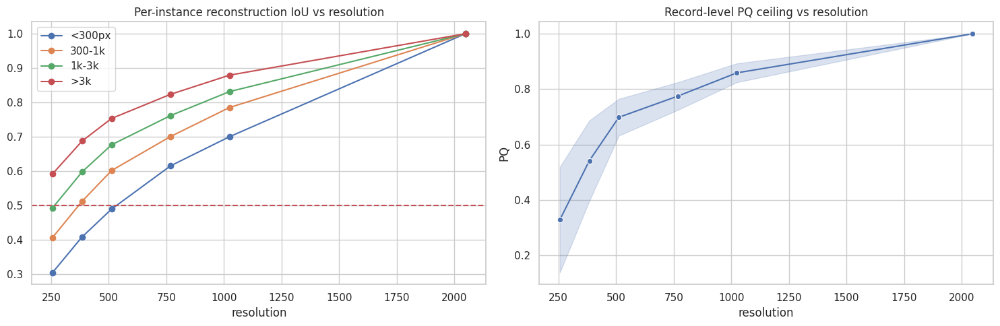


Reading guide: the resolution where PQ ceiling drops below ~0.9 is the
point where downsampling alone costs more than typical model errors.


In [34]:
# Record-level PQ ceiling per resolution: if the ONLY error were
# rasterization at resolution R, what PQ would a perfect model score?
CACHE8B = OUT / "a8_record_pq.csv"

if CACHE8B.exists():
    respq_df = pd.read_csv(CACHE8B)
else:
    rec_sample = random.sample(list(images_info.keys()), 40)
    rows = []
    for img_id in tqdm(rec_sample):
        info = images_info[img_id]
        h, w = info["height"], info["width"]
        gt = [ann_to_mask(a, h, w, 1.0) for a in anns_by_image[img_id]]
        for R in RESOLUTIONS:
            s = R / 2048.0
            recon = []
            for a in anns_by_image[img_id]:
                m = ann_to_mask(a, h, w, s)
                m = cv2.resize(m.astype(np.uint8), (w, h),
                               interpolation=cv2.INTER_NEAREST).astype(bool)
                if m.sum() > 0:
                    recon.append(m)
            pq = panoptic_quality(gt, recon)
            rows.append({"image_id": img_id, "resolution": R, **pq})
    respq_df = pd.DataFrame(rows); respq_df.to_csv(CACHE8B, index=False)

print("=== PQ ceiling imposed by resolution alone (40 records) ===")
display(respq_df.groupby("resolution")[["PQ", "SQ", "RQ"]]
        .agg(["mean", "median"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for bin_name, g in surv_df.groupby("size_bin"):
    axes[0].plot(g.groupby("resolution")["iou"].mean(), marker="o", label=bin_name)
axes[0].set_title("Per-instance reconstruction IoU vs resolution")
axes[0].set_xlabel("resolution"); axes[0].legend(); axes[0].axhline(0.5, ls="--", c="r")
sns.lineplot(data=respq_df, x="resolution", y="PQ", marker="o",
             errorbar="sd", ax=axes[1])
axes[1].set_title("Record-level PQ ceiling vs resolution")
plt.tight_layout(); plt.savefig(OUT / "a8_resolution.png", dpi=100); plt.show()

print("\nReading guide: the resolution where PQ ceiling drops below ~0.9 is the")
print("point where downsampling alone costs more than typical model errors.")


A9

In [35]:
# ============================================================
# A9 | Systematic hard-case identification.
# Per-instance scores: size, contrast, elongation, branches, limb distance.
# Per-record scores: crowding, touching, inter-annotator disagreement.
# Output: hard_cases.csv + one gallery per category.
# ============================================================
CACHE9 = OUT / "a9_instance_scores.csv"

def skeleton_branch_count(mask):
    sk = morphology.skeletonize(mask).astype(np.uint8)
    if sk.sum() < 3:
        return 0, int(sk.sum())
    neigh = cv2.filter2D(sk, -1, np.ones((3, 3), np.uint8)) - sk
    return int(((neigh >= 3) & (sk > 0)).sum()), int(sk.sum())

if CACHE9.exists():
    hc_df = pd.read_csv(CACHE9)
else:
    RING = np.ones((31, 31), np.uint8)          # 15 px dilation ring
    rows = []
    anns_by_file = defaultdict(list)
    for img_id, info in images_info.items():
        anns_by_file[Path(info["file_name"]).name].append(img_id)

    for fname, ids in tqdm(anns_by_file.items()):
        if fname not in name_to_path:
            continue
        img = load_image(name_to_path[fname])
        h, w = img.shape
        for img_id in ids:
            for a in anns_by_image[img_id]:
                polys = [np.asarray(p, np.float64).reshape(-1, 2)
                         for p in a["segmentation"]]
                allpts = np.vstack(polys)
                x0 = max(0, int(allpts[:, 0].min()) - 20)
                y0 = max(0, int(allpts[:, 1].min()) - 20)
                x1 = min(w, int(allpts[:, 0].max()) + 20)
                y1 = min(h, int(allpts[:, 1].max()) + 20)
                if x1 - x0 < 3 or y1 - y0 < 3:
                    continue
                crop = img[y0:y1, x0:x1]
                m = np.zeros(crop.shape, np.uint8)
                for p in polys:
                    cv2.fillPoly(m, [np.round(p - [x0, y0]).astype(np.int32)], 1)
                mb = m.astype(bool)
                area = int(mb.sum())
                if area < 5:
                    continue
                ring = cv2.dilate(m, RING).astype(bool) & ~mb
                contrast = float(crop[ring].mean() - crop[mb].mean()) if ring.any() else np.nan
                branches, skel_len = skeleton_branch_count(mb)
                thickness = area / max(skel_len, 1)
                cx, cy = allpts[:, 0].mean(), allpts[:, 1].mean()
                rows.append({
                    "ann_id": a["id"], "image_id": img_id, "file": fname,
                    "cat": CAT_NAMES[a["category_id"]],
                    "area": area, "contrast": contrast,
                    "skel_len": skel_len, "thickness": thickness,
                    "elongation": skel_len / max(thickness, 1e-6),
                    "branches": branches,
                    "r_norm": math.hypot(cx - w/2, cy - h/2) / (w/2),
                    "cx": cx, "cy": cy,
                })
    hc_df = pd.DataFrame(rows); hc_df.to_csv(CACHE9, index=False)

print(f"Scored instances: {len(hc_df)}")
display(hc_df[["area", "contrast", "elongation", "branches", "r_norm"]]
        .describe().round(2))


  0%|          | 0/707 [00:00<?, ?it/s]

Scored instances: 8199


,area,contrast,elongation,branches,r_norm
count,8199.00,8199.00,8199.00,8199.00,8199.00
mean,2293.13,14.51,16.21,13.58,0.50
std,2858.75,5.40,13.51,16.49,0.18
min,18.00,-7.04,0.02,0.00,0.01
25%,757.50,10.61,7.02,1.00,0.37
50%,1365.00,13.88,12.71,8.00,0.51
75%,2646.00,17.91,21.08,20.00,0.64
max,39060.00,42.21,171.45,186.00,0.85


In [36]:
# Record-level hard scores + category flags
rec_hard = (hc_df.groupby("image_id")
            .agg(file=("file", "first"), n_inst=("ann_id", "count"),
                 min_area=("area", "min"), min_contrast=("contrast", "min"),
                 max_elong=("elongation", "max"), max_branches=("branches", "max"),
                 max_rnorm=("r_norm", "max"))
            .reset_index())

# merge disagreement (min pairwise dice per file, from A1)
dis = pair_df.groupby("file")["dice"].min().rename("min_pair_dice")
rec_hard = rec_hard.merge(dis, on="file", how="left")

# merge touching (from A6)
touch3 = (touch_df[touch_df.k_px == 3].set_index("image_id")["n_close_pairs"]
          .rename("close_pairs_3px"))
rec_hard = rec_hard.merge(touch3, on="image_id", how="left")

# thresholds: empirical percentiles, printed for transparency
TH = {
    "tiny":        ("min_area",       hc_df["area"].quantile(0.05), "<"),
    "low_contrast":("min_contrast",   hc_df["contrast"].quantile(0.05), "<"),
    "elongated":   ("max_elong",      hc_df["elongation"].quantile(0.95), ">"),
    "branchy":     ("max_branches",   hc_df["branches"].quantile(0.95), ">"),
    "limb":        ("max_rnorm",      0.85, ">"),
    "crowded":     ("n_inst",         rec_hard["n_inst"].quantile(0.95), ">"),
    "touching":    ("close_pairs_3px", 0, ">"),
    "disagreement":("min_pair_dice",  pair_df["dice"].quantile(0.10), "<"),
}
for name, (col, thr, op) in TH.items():
    rec_hard[f"is_{name}"] = (rec_hard[col] < thr) if op == "<" else (rec_hard[col] > thr)
    print(f"{name:>13}: {col} {op} {thr:.1f}  ->  {rec_hard[f'is_{name}'].sum()} records")

rec_hard["hard_score"] = rec_hard[[f"is_{k}" for k in TH]].sum(axis=1)
rec_hard.to_csv(OUT / "hard_cases.csv", index=False)
print(f"\nSaved {OUT/'hard_cases.csv'}  | records with >=2 hard flags: "
      f"{(rec_hard['hard_score'] >= 2).sum()}")


         tiny: min_area < 369.0  ->  262 records
 low_contrast: min_contrast < 6.6  ->  276 records
    elongated: max_elong > 42.5  ->  315 records
      branchy: max_branches > 45.0  ->  295 records
         limb: max_rnorm > 0.8  ->  0 records
      crowded: n_inst > 15.0  ->  55 records
     touching: close_pairs_3px > 0.0  ->  56 records
 disagreement: min_pair_dice < 0.5  ->  109 records

Saved nb02_outputs/hard_cases.csv  | records with >=2 hard flags: 408


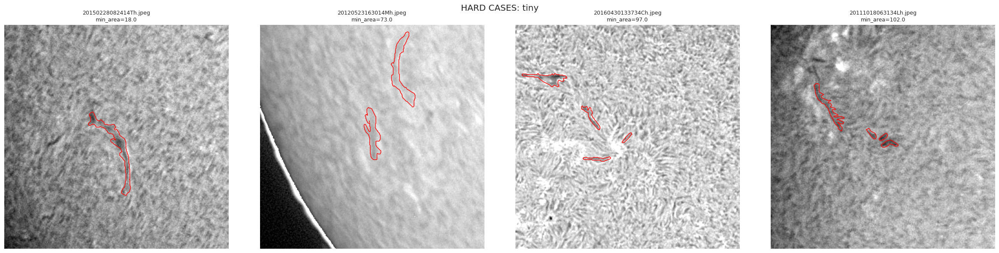

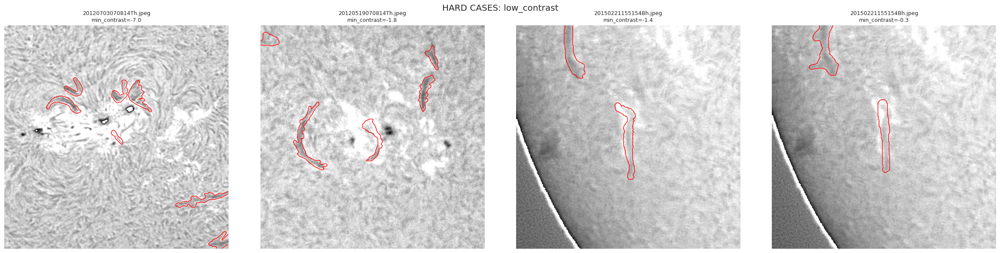

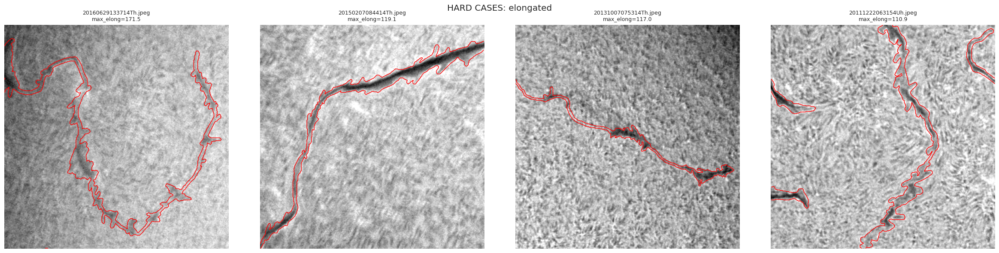

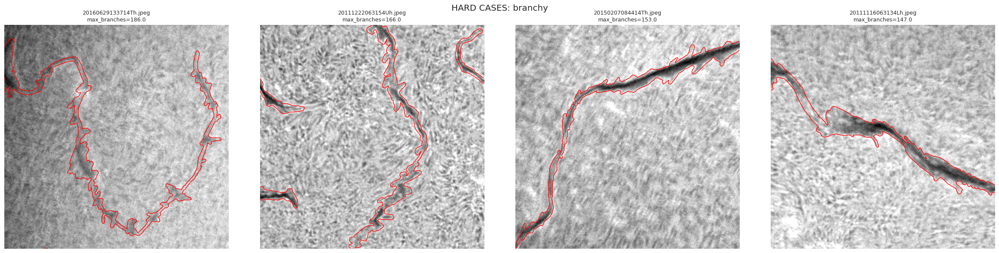

[limb] no examples


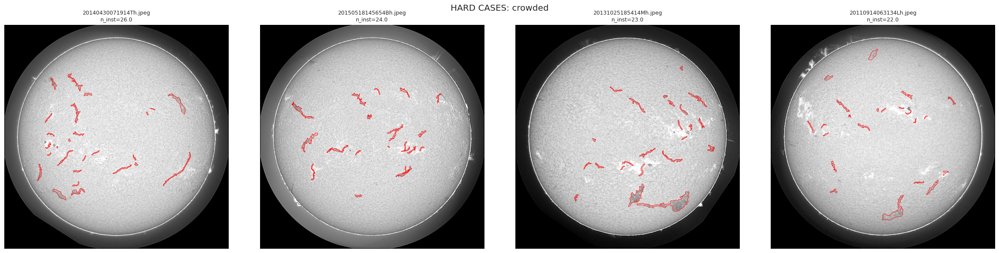

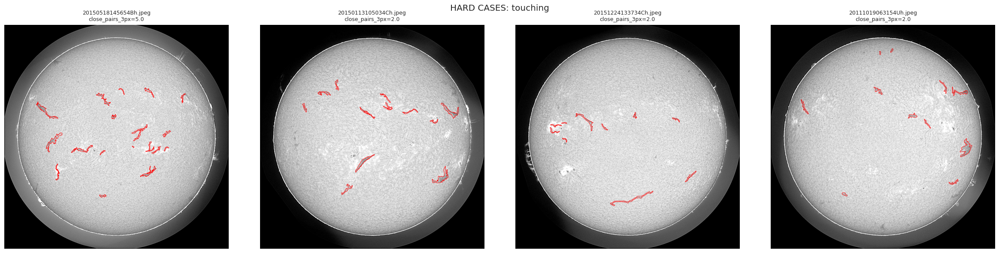

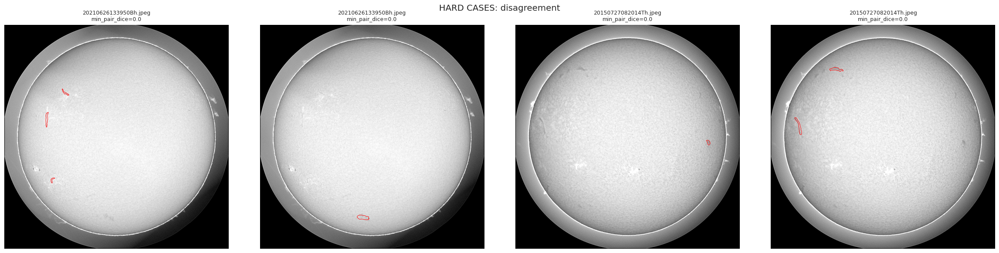

In [37]:
# Galleries: top-4 per category, zoomed to the offending instance where sensible
def gallery(category, n=4):
    col, thr, op = TH[category]
    sub = rec_hard[rec_hard[f"is_{category}"]]
    sub = sub.sort_values(col, ascending=(op == "<")).head(n)
    if len(sub) == 0:
        print(f"[{category}] no examples"); return
    fig, axes = plt.subplots(1, len(sub), figsize=(6 * len(sub), 6))
    for ax, (_, r) in zip(np.atleast_1d(axes), sub.iterrows()):
        img = norm01(load_image(name_to_path[r["file"]]))
        masks = record_instance_masks(r["image_id"], 1.0)
        comb = np.any(masks, axis=0)
        if category in ("tiny", "low_contrast", "elongated", "branchy", "limb"):
            inst = hc_df[hc_df["image_id"] == r["image_id"]]
            key = {"tiny": ("area", True), "low_contrast": ("contrast", True),
                   "elongated": ("elongation", False), "branchy": ("branches", False),
                   "limb": ("r_norm", False)}[category]
            worst = inst.sort_values(key[0], ascending=key[1]).iloc[0]
            cx, cy = int(worst["cx"]), int(worst["cy"])
            y0, y1 = max(0, cy-200), min(img.shape[0], cy+200)
            x0, x1 = max(0, cx-200), min(img.shape[1], cx+200)
            ax.imshow(img[y0:y1, x0:x1], cmap="gray")
            ax.contour(comb[y0:y1, x0:x1], levels=[0.5], colors="red", linewidths=1)
        else:
            ax.imshow(img, cmap="gray")
            ax.contour(comb, levels=[0.5], colors="red", linewidths=0.6)
        ax.set_title(f"{r['file']}\n{col}={r[col]:.1f}", fontsize=9)
        ax.axis("off")
    plt.suptitle(f"HARD CASES: {category}")
    plt.tight_layout()
    plt.savefig(OUT / f"a9_gallery_{category}.png", dpi=90)
    plt.show()

for cat in TH:
    gallery(cat)
